# 08 · Choosing the embedding model

Every mapping method in D1 picks a standard group from the same **shortlist of the 10 closest groups**, found with an embedding model (notebook 07 shows how one shortlist is built). If the right group is not on that shortlist, no method can find it. So the shortlist sets a ceiling for the whole project, and the model behind it is the first choice to get right.

This notebook compares the three candidate models on the **dev split** (3,500 synthetic accounts in Dutch, French, English and mixed). The test split stays unseen.

| model | what it is | size |
|---|---|---|
| `intfloat/multilingual-e5-base` (**e5-base**) | general multilingual retrieval model; needs `query:` / `passage:` prefixes | 278M parameters, 768-dim vectors |
| `BAAI/bge-m3` (**bge-m3**) | larger multilingual retrieval model, long inputs | 568M parameters, 1024-dim vectors |
| `sentence-transformers/paraphrase-multilingual-mpnet-base-v2` (**mpnet**) | trained to recognise paraphrases across languages | 278M parameters, 768-dim vectors |

**The rule, fixed before looking at the results:** the highest **recall@10** wins (how often the right group is on the shortlist), because it caps every method. Ties go to the better top-1, then to the faster model.

The numbers come from `python -m d1.evaluation.select_embedder`, which saved, for every account and every model, where the right group ranked among all 190 (`reports/embedding_selection_rows.csv`). This notebook only reads that file and its summary (`reports/embedding_selection.json`), so it runs in seconds without loading any model. The maths lives in `src/d1/evaluation/embedding_analysis.py`, where it is tested.

*Re-run on 2026-11-06 after the account names were cleaned of company, bank and brand names (notebook 04, section 3b).*

## The short answer

**bge-m3 wins.** Its shortlist of 10 contains the right group for **87.5%** of dev accounts, against 83.4% for e5-base and 71.3% for mpnet.
- **The lead is real, not luck:** +4.1 points over e5-base, with a 95% interval of +3.1 to +5.3 points when whole companies are resampled. It is also first in every language and on both kinds of accounts.
- **It is also the best first choice:** top-1 65.1%, against 59.0% and 39.6%.
- **Its only cost is speed:** 12 seconds for the 3,690 texts, against 5 for the others. For charts that are mapped once at onboarding, that does not matter, and speed is only the tie-breaker.

Two things the averages hide:
- **The LLM-written accounts are the real test.** bge-m3 finds 99.2% of rule-based accounts but 71.9% of LLM-written ones. Rule-based names are distorted *standard* names, so they stay close to the target text. The LLM writes like a bookkeeper: "Gross wages shop staff" for group 620, whose official name is "Remuneration and Direct Social Benefits". bge-m3 ranks it 47th.
- **8.8% of dev accounts are out of reach of all three models,** and with the winner alone 12.5% are. No mapping method can recover those, so they will always go to human review.

*The numbers in this text are from the run of `python -m d1.evaluation.select_embedder` saved in `reports/`; the cells below recompute them from that file.*

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_auc_score

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.embedding_analysis import (
    company_bootstrap_ci, head_to_head, load_rows, paired_difference, recall_by, recall_curve,
)
from d1.evaluation.plotting import COLORS as COLOR, INK, INK_2, MUTED, SURFACE, BLUE_RAMP, apply_style, short
from d1.evaluation.plotting import pct as pct_format
from d1.evaluation.select_embedder import choose_best

config = load_config()
K = config.models.mapping.candidates_k
df = load_rows(REPO_ROOT / "reports" / "embedding_selection_rows.csv")
summary = json.loads((REPO_ROOT / "reports" / "embedding_selection.json").read_text(encoding="utf-8"))
chart = {a.code: a for a in load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)}

MODELS = [m["model"] for m in summary["models"]]
apply_style()
pct = pct_format()
pd.set_option("display.max_colwidth", 60)

best = choose_best(summary["models"])["model"]
n_accounts = df["account_id"].nunique()
print(f"{n_accounts} dev accounts from {df['company_id'].nunique()} companies, {len(MODELS)} models, shortlist k = {K}")

3500 dev accounts from 70 companies, 3 models, shortlist k = 10


### The dev accounts

What the models are tested on. *rules* accounts are standard names distorted by noise rules (abbreviations, typos, cut-off names…); *llm* accounts were written from scratch by an LLM playing a bookkeeper, so they read more like real ledgers.

In [2]:
accounts = df[df["model"] == MODELS[0]]
display(pd.crosstab(accounts["language"], accounts["source"], margins=True, margins_name="total"))

source,llm,rules,total
language,,,
en,400,500,900
fr,400,500,900
mixed,350,500,850
nl,350,500,850
total,1500,2000,3500


## 1. How good is each model?

Three ways to read the shortlist:
- **top-1**: the right group is the model's *first* choice. This is the embeddings-only baseline method.
- **top-3**: the right group is in the first three.
- **recall@10**: the right group is anywhere on the shortlist of 10. **This is the ceiling for every method**, and the number the choice is based on.

,top-1,top-3,recall@10,seconds,vector size
model,,,,,
e5-base,59.0%,73.9%,83.4%,5.0,768
bge-m3,65.1%,79.7%,87.5%,11.7,1024
mpnet,39.6%,57.9%,71.3%,4.2,768


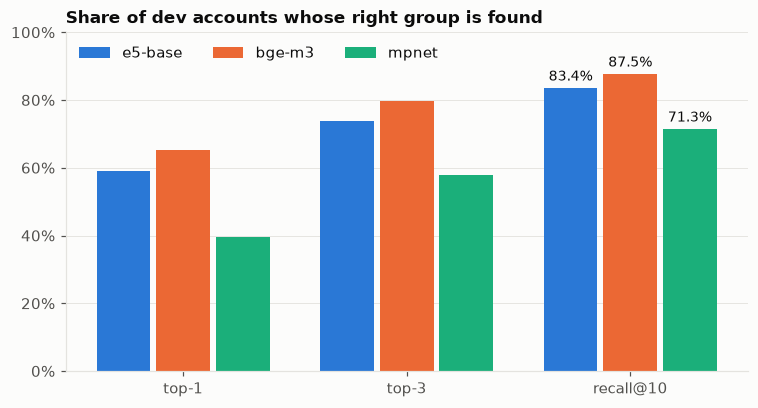

In [3]:
by_model = {m["model"]: m for m in summary["models"]}
headline = pd.DataFrame([
    {
        "model": short(m),
        "top-1": by_model[m]["top1"],
        "top-3": by_model[m]["top3"],
        f"recall@{K}": by_model[m]["recall_at_k"],
        "seconds": by_model[m]["seconds"],
        "vector size": by_model[m]["dim"],
    }
    for m in MODELS
]).set_index("model")
display(headline.style.format({"top-1": "{:.1%}", "top-3": "{:.1%}", f"recall@{K}": "{:.1%}", "seconds": "{:.1f}"}))

metrics = ["top1", "top3", "recall_at_k"]
labels = ["top-1", "top-3", f"recall@{K}"]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(metrics))
width = 0.8 / len(MODELS)
for i, m in enumerate(MODELS):
    values = [by_model[m][key] for key in metrics]
    bars = ax.bar(x + (i - (len(MODELS) - 1) / 2) * width, values, width * 0.9, color=COLOR[m], label=short(m))
    last = bars[-1]  # label the deciding metric only
    ax.annotate(f"{values[-1]:.1%}", (last.get_x() + last.get_width() / 2, values[-1]), xytext=(0, 3),
                textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(x, labels)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_title("Share of dev accounts whose right group is found")
ax.legend(loc="upper left", ncols=len(MODELS))
plt.show()

## 2. How does it change with the shortlist size?

The curve shows recall@k for every k from 1 to 30: how often the right group is within the first k candidates. The vertical line is the shortlist size D1 uses (k = 10). A steep curve after 10 would mean a longer shortlist is worth it. A flat one means the missing accounts are far down the list.

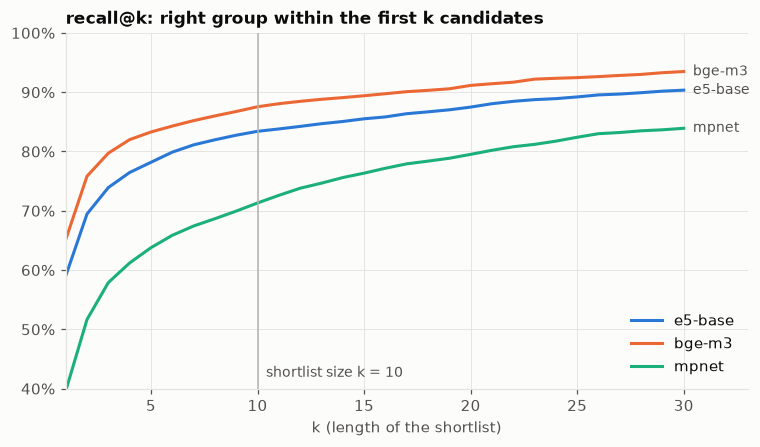

,e5-base,bge-m3,mpnet
k,,,
1,59.0%,65.1%,39.6%
3,73.9%,79.7%,57.9%
5,78.2%,83.3%,63.8%
10,83.4%,87.5%,71.3%
15,85.5%,89.4%,76.3%
20,87.5%,91.1%,79.5%
30,90.3%,93.5%,83.9%


In [4]:
ks = list(range(1, 31))
curve = recall_curve(df, ks)
fig, ax = plt.subplots(figsize=(8, 4.2))
for m in MODELS:
    ax.plot(ks, curve[m], color=COLOR[m], label=short(m))
    ax.annotate(short(m), (ks[-1], curve.loc[ks[-1], m]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.axvline(K, color=MUTED, linewidth=1)
ax.text(K + 0.4, 0.42, f"shortlist size k = {K}", color=INK_2, fontsize=9)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0.4, 1)
ax.set_xlim(1, 33)
ax.set_xlabel("k (length of the shortlist)")
ax.set_title("recall@k: right group within the first k candidates")
ax.legend(loc="lower right")
plt.show()

display(curve.loc[[1, 3, 5, 10, 15, 20, 30]].rename(columns=short).style.format("{:.1%}"))

## 3. Is the difference real, or luck?

Dev has 3,500 accounts, but they come from only 70 companies. Accounts of one company share a style (language, abbreviations, the LLM that wrote them), so they are not 3,500 independent tries. The intervals below resample **whole companies** (2,000 times) and give the range recall@10 would plausibly take on another set of 70 companies. That is wider, and more honest, than resampling single accounts.

The second table compares the winner with each other model **on the same resamples**. If the whole interval of the difference is above zero, the winner is better beyond reasonable doubt.

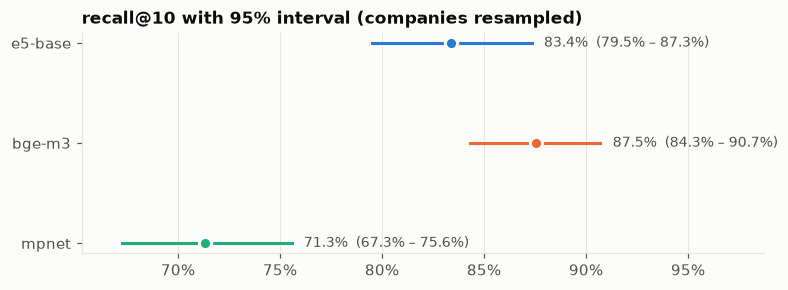

,difference,95% low,95% high,clearly better
comparison,,,,
bge-m3 minus e5-base,+4.1%,+3.1%,+5.3%,yes
bge-m3 minus mpnet,+16.2%,+13.9%,+18.4%,yes


In [5]:
ci = company_bootstrap_ci(df, k=K, n_boot=2000, seed=0).set_index("model").loc[MODELS]
fig, ax = plt.subplots(figsize=(8, 2.6))
for y, m in enumerate(MODELS):
    row = ci.loc[m]
    ax.plot([row["low"], row["high"]], [y, y], color=COLOR[m], linewidth=2)
    ax.plot(row["recall"], y, "o", color=COLOR[m], markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{row['recall']:.1%}  ({row['low']:.1%} – {row['high']:.1%})", (row["high"], y),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_yticks(range(len(MODELS)), [short(m) for m in MODELS])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
lo, hi = ci["low"].min(), ci["high"].max()
ax.set_xlim(lo - 0.02, hi + 0.08)
ax.grid(axis="y", visible=False)
ax.set_title(f"recall@{K} with 95% interval (companies resampled)")
plt.show()

rows = []
for other in [m for m in MODELS if m != best]:
    diff, low, high = paired_difference(df, best, other, k=K, n_boot=2000, seed=0)
    rows.append({"comparison": f"{short(best)} minus {short(other)}", "difference": diff, "95% low": low,
                 "95% high": high, "clearly better": "yes" if low > 0 else "no"})
display(pd.DataFrame(rows).set_index("comparison").style.format({"difference": "{:+.1%}", "95% low": "{:+.1%}", "95% high": "{:+.1%}"}))

## 4. Head to head: do the models find the same accounts?

If two models missed exactly the same accounts, the better one simply dominates. If they miss *different* accounts, combining them could help later. The last line shows the accounts **no** model gets on the shortlist: those are out of reach for every method in this project, whichever embedding model we choose.

In [6]:
pairs = []
for i, a in enumerate(MODELS):
    for b in MODELS[i + 1:]:
        h = head_to_head(df, a, b, k=K)
        pairs.append({"model A": short(a), "model B": short(b), "both find it": h["both"],
                      "only A": h["only_a"], "only B": h["only_b"], "neither": h["neither"]})
display(pd.DataFrame(pairs).set_index(["model A", "model B"]))

ranks = df.pivot(index="account_id", columns="model", values="gold_rank")[MODELS]
missed_by_all = (ranks > K).all(axis=1)
print(f"No model has the right group in its top {K}: {missed_by_all.sum()} accounts ({missed_by_all.mean():.1%})")
print(f"At least one model has it: {(~missed_by_all).mean():.1%} (the ceiling if the models were combined)")

both find it  only A  only B  neither
model A model B                                       
e5-base bge-m3           2847      72     217      364
        mpnet            2368     551     128      453
bge-m3  mpnet            2416     648      80      356

No model has the right group in its top 10: 308 accounts (8.8%)
At least one model has it: 91.2% (the ceiling if the models were combined)


## 5. Where is each model strong or weak?

The same recall@10, split by the company's language and by who wrote the accounts. An accounting group with Belgian subsidiaries gets all four languages, so a model that is good on average but weak in French would be a real problem.

Note on *llm* rows: their labels are the generating LLM's own, not hand-checked. On the test split the hand check found 13% of those labels wrong, so the *llm* bars understate every model by a similar margin. The comparison *between* models still holds.

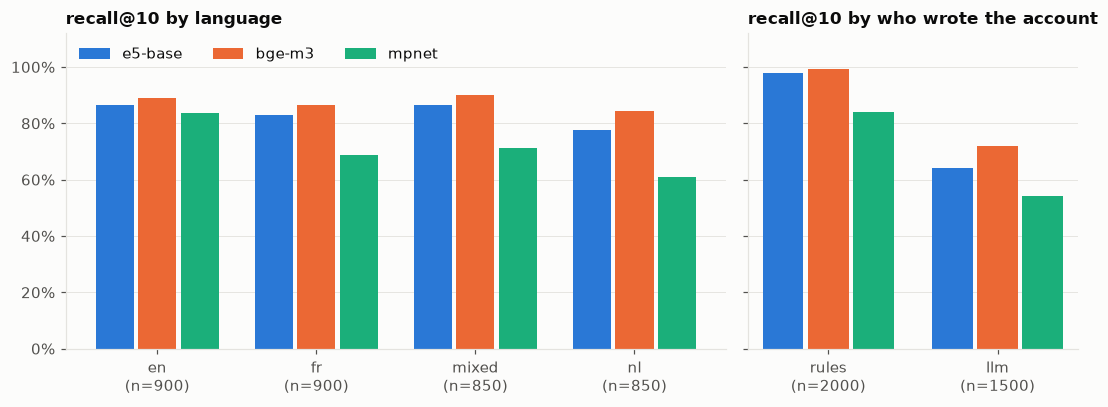

,e5-base,bge-m3,mpnet,n
en,86.6%,88.9%,83.8%,900
fr,82.9%,86.7%,68.7%,900
mixed,86.4%,90.1%,71.2%,850
nl,77.6%,84.5%,61.1%,850
rules,97.8%,99.2%,84.0%,2000
llm,64.3%,71.9%,54.3%,1500


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, gridspec_kw={"width_ratios": [4, 2]})
for ax, by, title in [(axes[0], "language", "by language"), (axes[1], "source", "by who wrote the account")]:
    table = recall_by(df, by, k=K)
    cats = list(table.index)
    x = np.arange(len(cats))
    width = 0.8 / len(MODELS)
    for i, m in enumerate(MODELS):
        ax.bar(x + (i - (len(MODELS) - 1) / 2) * width, table[m], width * 0.9, color=COLOR[m], label=short(m))
    ax.set_xticks(x, [f"{c}\n(n={table.loc[c, 'n']})" for c in cats])
    ax.grid(axis="x", visible=False)
    ax.set_title(f"recall@{K} {title}")
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_ylim(0, 1.12)
axes[0].set_yticks(np.linspace(0, 1, 6))
axes[0].legend(loc="upper left", ncols=len(MODELS))
plt.tight_layout()
plt.show()

display(pd.concat([recall_by(df, "language", k=K), recall_by(df, "source", k=K)])
        .rename(columns=short).style.format({short(m): "{:.1%}" for m in MODELS}))

## 6. Which kinds of mess hurt most?

Every rule-based account records the distortions applied to it (an account can have several, and then counts under each). *llm* marks the accounts written by the LLM, *legacy_code* those with an unrelated company numbering. A darker cell is a higher recall@10. Read across a row to see which model copes best with that kind of mess, and down a column to see what each model struggles with.

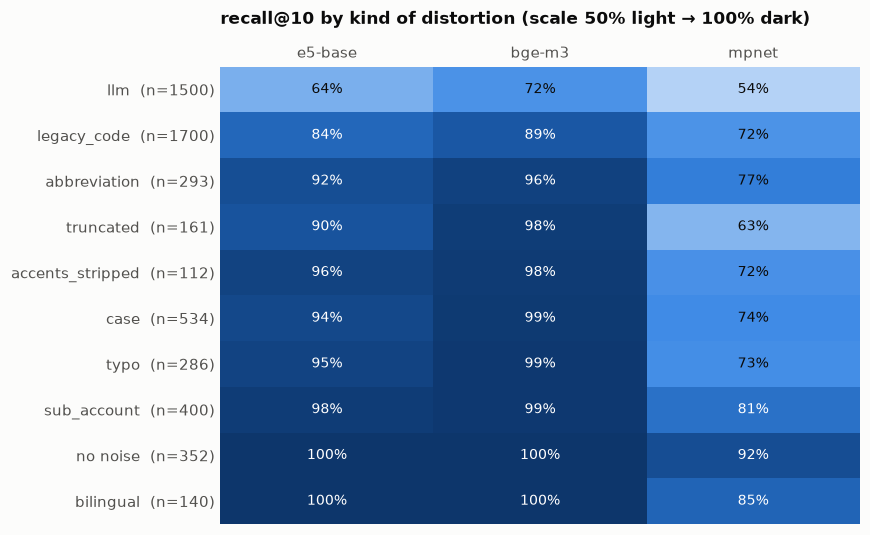

In [8]:
noise = recall_by(df, "noise", k=K)
noise = noise.sort_values(best)
values = noise[MODELS].to_numpy()
fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(noise) + 1.2))
from matplotlib.colors import LinearSegmentedColormap
ramp = LinearSegmentedColormap.from_list("blue", BLUE_RAMP)
ax.imshow(values, cmap=ramp, vmin=0.5, vmax=1.0, aspect="auto")
for (r, c), v in np.ndenumerate(values):
    ax.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.8 else INK)
ax.set_xticks(range(len(MODELS)), [short(m) for m in MODELS])
ax.set_yticks(range(len(noise)), [f"{tag}  (n={n})" for tag, n in zip(noise.index, noise["n"])])
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.xaxis.tick_top()
ax.set_title(f"recall@{K} by kind of distortion (scale 50% light → 100% dark)", pad=28)
plt.show()

## 7. When the right group is missing, how far off is it?

For the accounts whose right group is *not* in the top 10: where does it rank instead? Ranks 11–20 are near misses that a longer shortlist would catch. Ranks above 50 mean the model has misunderstood the name, and a longer list would not help.

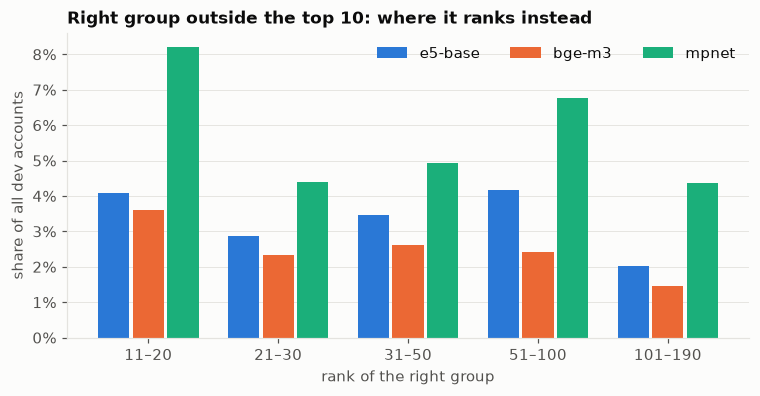

In [9]:
bins = [(11, 20), (21, 30), (31, 50), (51, 100), (101, 190)]
labels = [f"{a}–{b}" for a, b in bins]
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(bins))
width = 0.8 / len(MODELS)
for i, m in enumerate(MODELS):
    r = df.loc[df["model"] == m, "gold_rank"]
    shares = [((r >= a) & (r <= b)).mean() for a, b in bins]
    ax.bar(x + (i - (len(MODELS) - 1) / 2) * width, shares, width * 0.9, color=COLOR[m], label=short(m))
ax.set_xticks(x, labels)
ax.set_xlabel("rank of the right group")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylabel("share of all dev accounts")
ax.grid(axis="x", visible=False)
ax.set_title(f"Right group outside the top {K}: where it ranks instead")
ax.legend(ncols=len(MODELS))
plt.show()

## 8. Can the score tell right from wrong?

Later, D1 auto-maps an account only when it is confident enough. For the embeddings baseline, confidence comes from the cosine score of the first candidate. The charts below split the dev accounts by whether that first candidate is right (colour) or wrong (grey). The less the two shapes overlap, the more the score can be trusted.

The **AUC** in the table measures this separation: 0.5 is a coin flip, 1.0 is perfect. It is shown for the raw top-1 score and for the **margin** (top-1 score minus top-2 score). The calibration step (Task 2.3) uses both.

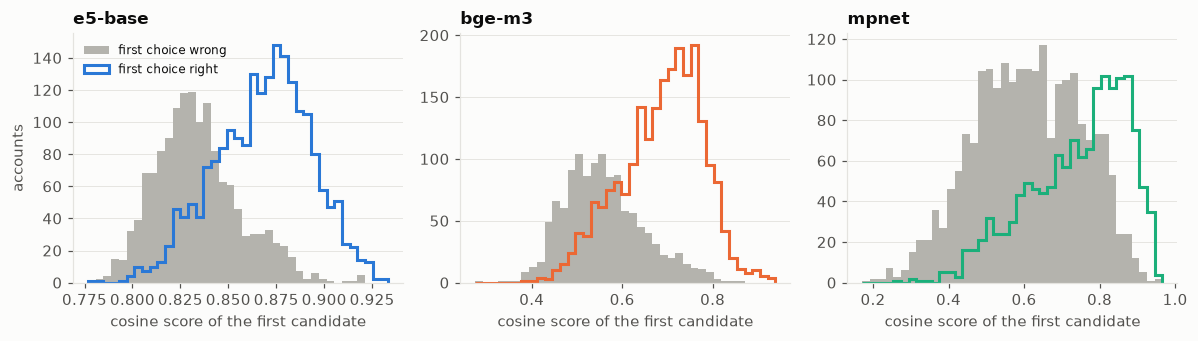

,AUC top-1 score,AUC margin
model,,
e5-base,0.842,0.795
bge-m3,0.839,0.825
mpnet,0.758,0.732


In [10]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(11, 3.2))
auc_rows = []
for ax, m in zip(axes, MODELS):
    rows = df[df["model"] == m]
    right = rows["gold_rank"] == 1
    bins = np.linspace(rows["top1_score"].min(), rows["top1_score"].max(), 40)
    ax.hist(rows.loc[~right, "top1_score"], bins=bins, color=MUTED, label="first choice wrong")
    ax.hist(rows.loc[right, "top1_score"], bins=bins, histtype="step", linewidth=2, color=COLOR[m], label="first choice right")
    ax.set_title(short(m))
    ax.set_xlabel("cosine score of the first candidate")
    ax.grid(axis="x", visible=False)
    auc_rows.append({"model": short(m),
                     "AUC top-1 score": roc_auc_score(right, rows["top1_score"]),
                     "AUC margin": roc_auc_score(right, rows["top1_score"] - rows["top2_score"])})
axes[0].set_ylabel("accounts")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(auc_rows).set_index("model").style.format("{:.3f}"))

## 9. Quality against speed

Seconds to embed the 190 standard groups and all 3,500 dev names, on the laptop that ran the comparison (model already loaded). The service maps a company's chart once at onboarding, so a few seconds more is no problem. Speed only matters as a tie-breaker.

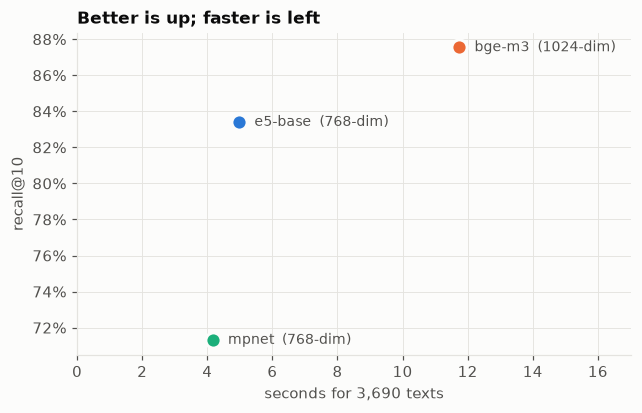

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for m in MODELS:
    s = by_model[m]
    ax.plot(s["seconds"], s["recall_at_k"], "o", color=COLOR[m], markersize=10, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{short(m)}  ({s['dim']}-dim)", (s["seconds"], s["recall_at_k"]), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_xlabel("seconds for 3,690 texts")
ax.set_ylabel(f"recall@{K}")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, max(s["seconds"] for s in summary["models"]) * 1.45)
ax.set_title("Better is up; faster is left")
plt.show()

## 10. Examples

Real dev accounts, to see *what* the numbers mean. The first table shows accounts the winner gets on the shortlist while both other models miss. The second shows accounts no model gets on the shortlist, with the winner's first three guesses instead.

In [12]:
info = df[df["model"] == best].set_index("account_id")
def group(code):
    return f"{code} {chart[code].name_en}"

others = [m for m in MODELS if m != best]
only_best = ranks[(ranks[best] <= K) & (ranks[others] > K).all(axis=1)]
sample = only_best.sample(min(8, len(only_best)), random_state=0).index
table = pd.DataFrame({
    "account name": info.loc[sample, "name"],
    "language": info.loc[sample, "language"],
    "right group": info.loc[sample, "target_code"].map(group),
    **{f"rank in {short(m)}": ranks.loc[sample, m] for m in MODELS},
})
display(Markdown(f"**Found only by {short(best)}** ({len(only_best)} accounts in total)"))
display(table.reset_index(drop=True))

none = ranks[missed_by_all]
sample = none.sample(min(8, len(none)), random_state=0).index
table = pd.DataFrame({
    "account name": info.loc[sample, "name"],
    "language": info.loc[sample, "language"],
    "right group": info.loc[sample, "target_code"].map(group),
    f"{short(best)}'s first 3 guesses": info.loc[sample, "top3_codes"].map(lambda codes: "; ".join(group(c) for c in codes)),
})
display(Markdown(f"**Missed by every model** ({len(none)} accounts in total)"))
display(table.reset_index(drop=True))

**Found only by bge-m3** (145 accounts in total)

,account name,language,right group,rank in e5-base,rank in bge-m3,rank in mpnet
0,ECARTS DE CONVERSION DES DEVISES,fr,655 Foreign Currency Translation Differences,15,1,66
1,Crean. cmmerciales - RDV actee,mixed,409 Trade Debtors - Amounts Written Down Recorded (-),18,5,19
2,LT loan subsidiary,en,281 Amounts Receivable From Affiliated Enterprises,21,10,11
3,ONSS à payer,fr,454 National Social Security Office,31,1,126
4,WIP projets clients - coût,mixed,320 Work in Progress - Acquisition Value,26,6,39
5,Wisselkoersverschillen (GBP/CHF),mixed,655 Foreign Currency Translation Differences,15,4,74
6,Voorschotten klanten implementatieprojecten,nl,426 Advance Payments on Contract in Progress (> 1 Year F...,12,6,43
7,RESULTATEN UIT DE OMREKENING VAN VREEMDE VALUTA,nl,655 Foreign Currency Translation Differences,11,2,49


**Missed by every model** (308 accounts in total)

,account name,language,right group,bge-m3's first 3 guesses
0,Projectgrond verkaveling Lokeren,nl,350 Immovable Property Intended for Sale - Acquisition V...,221 Buildings; 220 Land; 222 Developed Land
1,Lening dochter,nl,281 Amounts Receivable From Affiliated Enterprises,439 Other Loans; 174 Other Loans (> 1 Year); 422 Leasing...
2,Salaires bruts employés,fr,620 Remuneration and Direct Social Benefits,623 Other Personnel Costs; 622 Employers' Premiums for E...
3,Gross wages shop staff,en,620 Remuneration and Direct Social Benefits,"623 Other Personnel Costs; 602 Purchases of Services, Wo..."
4,WV diverse vorderingen,nl,419 Sundry Amounts Receivable - Amounts Written Down Rec...,416 Sundry Amounts Receivable; 370 Contracts in Progress...
5,Bonds - Belgian state OLO,en,520 Fixed-Income Securities - Acquisition Value,440 Suppliers; 441 Bills of Exchange Payable; 431 Credit...
6,Cash deposits recd - rented scaffolding,en,178 Guarantees Received in Cash (> 1 Year),570 Cash in Hand - Cash; 288 Cash Guarantees Paid; 539 F...
7,Wissels in omloop,nl,401 Trade Debtors - Bills Receivable,754 Exchange Differences; 654 Exchange Differences; 441 ...


## 11. Decision

**`embedding_model: BAAI/bge-m3`** in `config/models.yaml`, chosen by the rule stated at the top (highest recall@10).

What this means for the rest of the project:
- **The ceiling:** on dev, no method can get more than 87.5% of accounts right, and 71.9% of the LLM-written ones. A method that reaches, say, 80% has already made most of what is possible, and the report must say so instead of comparing it to 100%.
- **Shortlist size stays at 10.** k = 20 would add 3.6 points (87.5% → 91.1%) but doubles what Laya and the LLM must read, and Laya gets worse with more than about 20 options. It is a dev setting that can be revisited later with this notebook.
- **The confidence score:** bge-m3's top-1 score separates right from wrong about as well as e5's (AUC 0.839 vs 0.842), and its margin does so better (0.825 vs 0.795). That matters for calibration (Task 2.3).
- **An improvement to try later:** the 190 groups are embedded with their official names only. Many misses are everyday words the formal names lack ("wages", "salaires", "bonus", "huur"). Adding a short description per group, with the words bookkeepers actually use, could raise the ceiling. It would be measured on dev with this same notebook, never on test.